# Income Classification — UCI Adult Census Data

**Question:** Can we predict whether a person earns more than $50K a year from census information, and which factors matter most?

**Steps:** load data → clean → explore → encode → train logistic regression → evaluate → interpret the strongest predictors.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay)

RANDOM_STATE = 42
plt.rcParams["figure.dpi"] = 110

## 1. Load the data
The file has no header row, so we name the 15 columns ourselves (names from the UCI documentation).

In [2]:
cols = ["age", "workclass", "fnlwgt", "education", "education_num", "marital_status",
        "occupation", "relationship", "race", "sex", "capital_gain", "capital_loss",
        "hours_per_week", "native_country", "income"]
df = pd.read_csv("../data/adult.csv.gz", header=None, names=cols, skipinitialspace=True)
print(df.shape)
df.head()

(48842, 15)


,age,workclass,fnlwgt,education,education_num,marital_status,occupation,relationship,race,sex,capital_gain,capital_loss,hours_per_week,native_country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


## 2. Clean the data
Missing values are stored as `?`. We turn them into real missing values, count them, and drop those rows (they are a small share).

In [3]:
df = df.replace("?", np.nan)
print("Missing values per column:\n", df.isna().sum()[df.isna().sum() > 0])
rows_before = len(df)
df = df.dropna().drop_duplicates()
print(f"Rows before: {rows_before:,}  after cleaning: {len(df):,}  removed: {rows_before - len(df):,}")

# Target: 1 if income > 50K, else 0
df["target"] = (df["income"].str.strip() == ">50K").astype(int)
# fnlwgt is a survey sampling weight, not a personal trait; education duplicates education_num
df = df.drop(columns=["income", "fnlwgt", "education"])
# Many countries have only a handful of rows, which makes their coefficients noisy.
# Group them: United-States vs Other. Also merge the rare "Married-AF-spouse" (armed forces) into "Married-civ-spouse".
df["native_country"] = np.where(df["native_country"] == "United-States", "United-States", "Other")
df["marital_status"] = df["marital_status"].replace({"Married-AF-spouse": "Married-civ-spouse"})
print(f"Share earning >50K: {df['target'].mean():.1%}")

Missing values per column:
 workclass         2799
occupation        2809
native_country     857
dtype: int64
Rows before: 48,842  after cleaning: 45,175  removed: 3,667
Share earning >50K: 24.8%


## 3. Explore
The classes are imbalanced (roughly 1 in 4 earns >50K), so accuracy alone would be misleading. We will also report precision, recall, F1 and ROC-AUC.

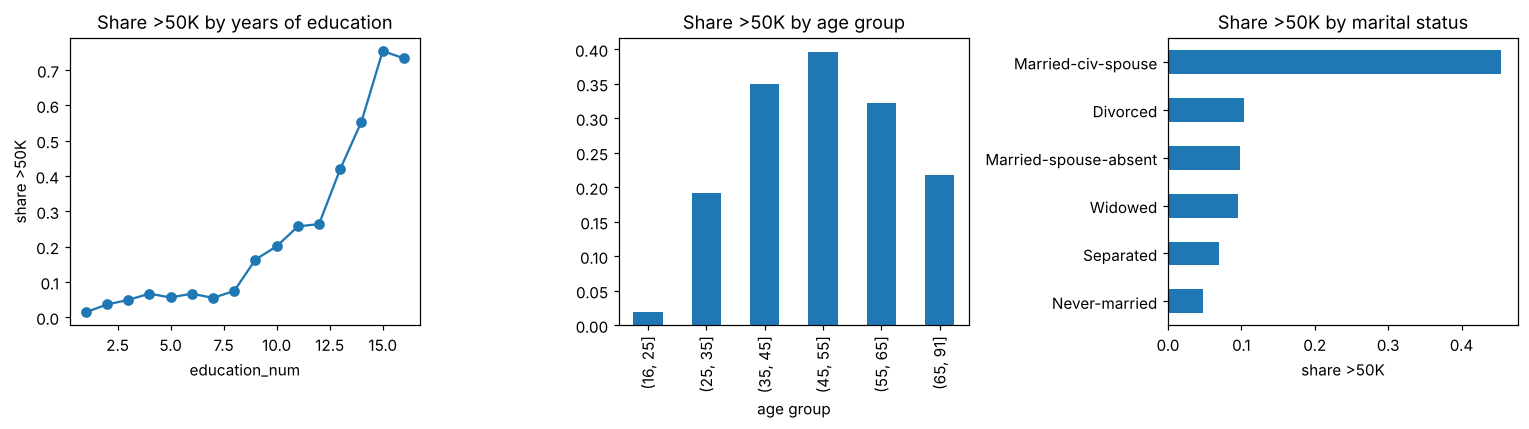

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
df.groupby("education_num")["target"].mean().plot(ax=axes[0], marker="o")
axes[0].set(title="Share >50K by years of education", xlabel="education_num", ylabel="share >50K")
df.groupby(pd.cut(df["age"], [16, 25, 35, 45, 55, 65, 91]), observed=True)["target"].mean().plot.bar(ax=axes[1])
axes[1].set(title="Share >50K by age group", xlabel="age group", ylabel="")
df.groupby("marital_status")["target"].mean().sort_values().plot.barh(ax=axes[2])
axes[2].set(title="Share >50K by marital status", xlabel="share >50K", ylabel="")
plt.tight_layout(); plt.savefig("../images/eda.png", bbox_inches="tight"); plt.show()

## 4. Train / test split and preprocessing
- 80% train, 20% test, **stratified** so both keep the same >50K share.
- Numeric columns are **standardized** (mean 0, sd 1) so coefficients are comparable.
- Text (categorical) columns are **one-hot encoded** (one 0/1 column per category).

In [5]:
X = df.drop(columns="target"); y = df["target"]
num_cols = X.select_dtypes("number").columns.tolist()
cat_cols = [c for c in X.columns if c not in num_cols]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

preprocess = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore", drop="first"), cat_cols),
])
model = Pipeline([("prep", preprocess), ("clf", LogisticRegression(max_iter=2000))])
print("numeric:", num_cols); print("categorical:", cat_cols)

numeric: ['age', 'education_num', 'capital_gain', 'capital_loss', 'hours_per_week']
categorical: ['workclass', 'marital_status', 'occupation', 'relationship', 'race', 'sex', 'native_country']


## 5. Baseline vs logistic regression
A baseline that always guesses "≤50K" tells us what accuracy we get for free. 5-fold cross-validation on the training set checks the model is stable before we touch the test set.

In [6]:
baseline = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
print(f"Baseline accuracy (always ≤50K): {accuracy_score(y_test, baseline.predict(X_test)):.3f}")

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_auc = cross_val_score(model, X_train, y_train, cv=cv, scoring="roc_auc")
print(f"5-fold CV ROC-AUC: {cv_auc.mean():.3f} ± {cv_auc.std():.3f}")

model.fit(X_train, y_train)
pred = model.predict(X_test); proba = model.predict_proba(X_test)[:, 1]
metrics = {
    "accuracy": accuracy_score(y_test, pred), "precision": precision_score(y_test, pred),
    "recall": recall_score(y_test, pred), "f1": f1_score(y_test, pred), "roc_auc": roc_auc_score(y_test, proba),
}
pd.Series(metrics).round(3).to_frame("test set")

Baseline accuracy (always ≤50K): 0.752


5-fold CV ROC-AUC: 0.905 ± 0.003


,test set
accuracy,0.845
precision,0.733
recall,0.588
f1,0.652
roc_auc,0.900


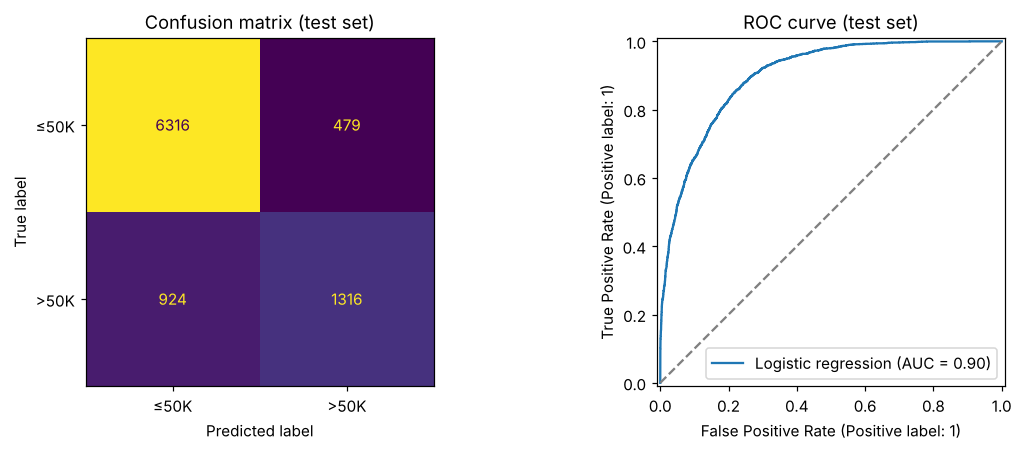

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
ConfusionMatrixDisplay(confusion_matrix(y_test, pred), display_labels=["≤50K", ">50K"]).plot(ax=axes[0], colorbar=False)
axes[0].set_title("Confusion matrix (test set)")
RocCurveDisplay.from_predictions(y_test, proba, ax=axes[1], name="Logistic regression")
axes[1].plot([0, 1], [0, 1], "--", color="grey"); axes[1].set_title("ROC curve (test set)")
plt.tight_layout(); plt.savefig("../images/evaluation.png", bbox_inches="tight"); plt.show()

## 6. Which factors matter most?
Because numeric inputs are standardized, coefficient size shows strength. A positive coefficient raises the odds of earning >50K; `exp(coef)` is the **odds ratio**.
Categorical coefficients are relative to the dropped first category of that column.

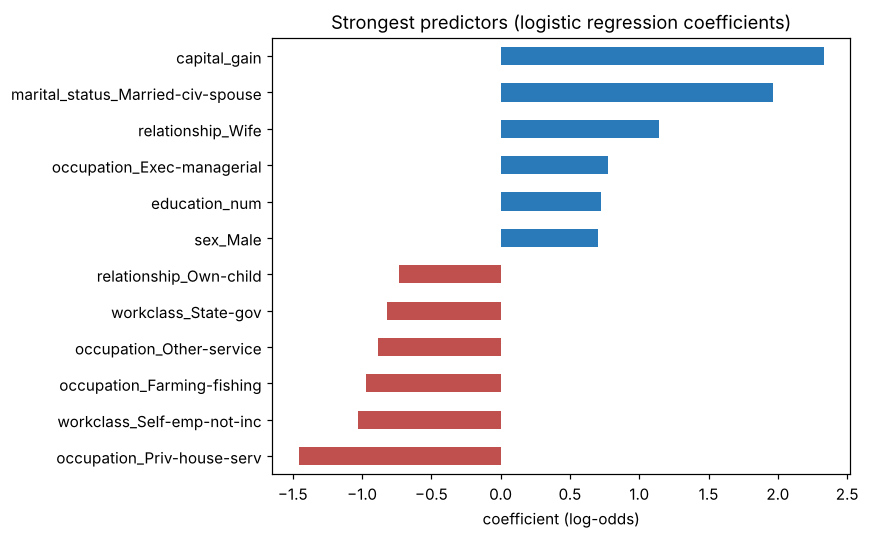

,feature,coef,odds_ratio
2,capital_gain,2.332,10.295
11,marital_status_Married-civ-spouse,1.966,7.139
23,occupation_Priv-house-serv,-1.458,0.233
33,relationship_Wife,1.143,3.136
8,workclass_Self-emp-not-inc,-1.032,0.356
19,occupation_Farming-fishing,-0.975,0.377
22,occupation_Other-service,-0.885,0.413
9,workclass_State-gov,-0.820,0.440
18,occupation_Exec-managerial,0.776,2.172
31,relationship_Own-child,-0.736,0.479


In [8]:
feat_names = model.named_steps["prep"].get_feature_names_out()
coefs = pd.DataFrame({"feature": feat_names, "coef": model.named_steps["clf"].coef_[0]})
coefs["odds_ratio"] = np.exp(coefs["coef"])
coefs["feature"] = coefs["feature"].str.replace("num__", "").str.replace("cat__", "")
top = coefs.reindex(coefs["coef"].abs().sort_values(ascending=False).index).head(12)

ax = top.sort_values("coef").plot.barh(x="feature", y="coef", legend=False, figsize=(8, 5),
                                        color=np.where(top.sort_values("coef")["coef"] > 0, "#2a7ab9", "#c0504d"))
ax.set(title="Strongest predictors (logistic regression coefficients)", xlabel="coefficient (log-odds)", ylabel="")
plt.tight_layout(); plt.savefig("../images/top_predictors.png", bbox_inches="tight"); plt.show()
top.round(3)

## 7. Plain-language takeaways
Read these together with the table above (numbers are odds ratios, so 2.0 means "twice the odds"):
- **Capital gains** is the strongest single predictor: one standard deviation more multiplies the odds of earning >50K by about 10. Few people have capital gains, but those who do usually earn a lot.
- **Being married** (civilian spouse) multiplies the odds by about 7 compared with never-married people. This mostly reflects age and household patterns, not marriage itself.
- **Education** matters steadily: each standard deviation more education (about 2.6 years) roughly doubles the odds.
- **Occupation** splits strongly: executive/managerial roles raise the odds, while private household service, farming/fishing and "other service" lower them.
- Being **self-employed (not incorporated)** or in **state government** lowers the odds compared with the reference work class.

**Model quality:** about 84% accuracy against a 75% "always ≤50K" baseline, and ROC-AUC about 0.90, so the model ranks people well. Recall for >50K is about 59%: it misses roughly 4 in 10 high earners, which a lower decision threshold could trade for more false alarms.

**Limitations:** the data is from the 1994 US Census, so dollar thresholds and patterns are dated; the model shows association, not cause; and sensitive attributes (sex, race) are included only to describe patterns in the data. They should not drive real decisions about people.

In [9]:
pd.Series(metrics).round(4).to_csv("../images/metrics.csv", header=["value"])